# Anexo B: experimentos de modelado
Respaldo técnico de la sección 4 del cuaderno principal. Reúne las comparaciones que ayudan a entender por qué un ensamble de cuatro modelos fue la primera elección: cada variante de la regresión logística y cada modelo con agrupamiento frente a la logística de referencia, el efecto del tamaño del ensamble en la combinatoria y las alternativas de agrupamiento de días frente a K-Means. Las probabilidades de los 17 candidatos día a día se leen de `../figuras/wf_probabilidades.pkl` (si no existe, se recalculan). Las decisiones adoptadas se declaran en la celda de configuración.

**Aviso (23-nov-2026).** Este anexo conserva el protocolo anterior a la corrección: «desarrollo» son los días 14–19 y «confirmación» los días 20–33, que incluyen la semana de prueba. Por eso sus rankings y cifras son **exploratorios y no sirven para elegir el modelo**. La selección válida, que usa solo los días 14–26 y abre la prueba una sola vez, está en el cuaderno principal (4.2.1 y 4.4); allí el modelo final resulta ser la combinación persistencia-climatología y no un ensamble.

## B.1 Preparación
Se reconstruyen el dataset, las particiones y los 17 candidatos con las mismas funciones del cuaderno principal, y se cargan sus probabilidades día a día.

In [1]:
import os, glob, zipfile, warnings, contextlib, io, itertools, json, sys, time, pickle
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, statsmodels, sklearn, xgboost, missingno as msno, joblib
from scipy import stats
from IPython.display import display
from sklearn.base import clone, BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.calibration import CalibratedClassifierCV
from sklearn.cluster import KMeans
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix, cohen_kappa_score,
                             ConfusionMatrixDisplay, classification_report, silhouette_score, mean_squared_error, mean_absolute_error)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from xgboost import XGBClassifier

SEMILLA = 42                                   # no es una decisión analítica: solo reproducibilidad
np.random.seed(SEMILLA)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)    # saga con pocas filas avisa a veces; no cambia las conclusiones
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)
os.makedirs('figuras', exist_ok=True)
print('Versiones -> python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__, '| matplotlib', matplotlib.__version__,
      '| seaborn', sns.__version__, '| scipy', scipy.__version__, '| statsmodels', statsmodels.__version__, '| scikit-learn', sklearn.__version__,
      '| xgboost', xgboost.__version__, '| missingno', msno.__version__, '| joblib', joblib.__version__)

Versiones -> python 3.13.3 | pandas 3.1.1 | numpy 2.5.4 | matplotlib 3.11.2 | seaborn 0.13.2 | scipy 1.18.1 | statsmodels 0.15.0 | scikit-learn 1.9.1 | xgboost 3.4.1 | missingno 0.5.2 | joblib 1.6.0


In [2]:
def buscar_datos(archivo='Plant_2_Weather_Sensor_Data.csv', carpetas=('.', 'Solar_Power', '../../Solar_Power', '../Data', 'datos_solar')):
    """Devuelve la carpeta donde están los CSV del dataset de Kaggle."""
    for carpeta in carpetas:
        hallados = glob.glob(os.path.join(carpeta, '**', archivo), recursive=True)
        if hallados:
            return os.path.dirname(hallados[0])
    for ruta_zip in glob.glob('*.zip'):
        with zipfile.ZipFile(ruta_zip) as z:
            if any(n.endswith(archivo) for n in z.namelist()):
                z.extractall('datos_solar')
                return buscar_datos(archivo, ('datos_solar',))
    raise FileNotFoundError(f'No se encontró {archivo}. Descarguen el ZIP desde Kaggle y déjenlo en la carpeta del notebook.')

def agregar_rezagos(df, columna, pasos=(1, 2, 4), freq='15min'):
    """Rezagos por fecha (no por posición): si falta el registro anterior queda NaN."""
    serie = df.set_index('DATE_TIME')[columna]
    if not serie.index.is_unique:
        raise ValueError('Hay fechas repetidas: agreguen o eliminen duplicados primero.')
    for p in pasos:
        pasado = serie.shift(p, freq=freq)
        df[f'{columna}_lag{p}'] = df['DATE_TIME'].map(pasado)
    return df

def crear_niveles(train, test, columna, n_niveles=3, etiquetas=None, umbrales=None, nombre='nivel'):
    """Variable objetivo por cuantiles de TRAIN, aplicados igual a test."""
    if umbrales is None:
        cortes = [float(train[columna].quantile(i / n_niveles)) for i in range(1, n_niveles)]
    else:
        cortes = sorted(float(u) for u in umbrales); n_niveles = len(cortes) + 1
    if len(set(cortes)) != len(cortes):
        raise ValueError(f'Cortes repetidos {cortes}.')
    if etiquetas is None:
        etiquetas = {2: ['bajo', 'alto'], 3: ['bajo', 'medio', 'alto']}.get(n_niveles, [f'nivel_{i + 1}' for i in range(n_niveles)])
    limites = [-np.inf] + cortes + [np.inf]
    train, test = train.copy(), test.copy()
    for d_ in (train, test):
        d_[nombre] = pd.cut(d_[columna], bins=limites, labels=etiquetas)
    print('Cortes (calculados con train):', [round(c, 1) for c in cortes])
    print('Proporción por clase en train:', train[nombre].value_counts(normalize=True).round(2).to_dict())
    print('Proporción por clase en test: ', test[nombre].value_counts(normalize=True).round(2).to_dict())
    return train, test, cortes

COLS_SENSOR = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']

def construir_malla(gen, sen):
    """Pasa a formato ancho sobre la malla completa de instantes de 15 min (los ausentes quedan vacíos)."""
    ac = gen.pivot(index='DATE_TIME', columns='SOURCE_KEY', values='AC_POWER')
    dc = gen.pivot(index='DATE_TIME', columns='SOURCE_KEY', values='DC_POWER')
    malla = pd.date_range(gen.DATE_TIME.min().normalize(), gen.DATE_TIME.max().normalize() + pd.Timedelta(hours=23, minutes=45),
                          freq='15min', name='DATE_TIME')
    ac, dc = ac.reindex(malla), dc.reindex(malla)
    d = sen.set_index('DATE_TIME')[COLS_SENSOR].reindex(malla)
    d['n_inv'] = ac.notna().sum(axis=1)                 # inversores que reportan
    d['AC_OBS_KW'] = ac.sum(axis=1, min_count=1)        # suma observada
    d['n_inv_cero'] = (ac == 0).sum(axis=1)             # inversores que reportan AC = 0
    return ac, dc, d

def _params_activos(ac_w, cols, idx):
    """Por cada inversor ausente: r (su potencia frente al promedio de los que producen) y p0 (frecuencia de AC = 0 con sol)."""
    pe = ac_w.loc[idx].drop(columns=cols)
    prom_act = pe.where(pe > 0).mean(axis=1)
    r = {c: (ac_w.loc[idx, c].where(ac_w.loc[idx, c] > 0) / prom_act).mean() for c in cols}
    p0 = {c: (ac_w.loc[idx, c] == 0).mean() for c in cols}
    return r, p0

def _ausentes(ac_w, cols, r, p0):
    """Potencia que habrían aportado los inversores `cols` en las filas de ac_w."""
    pres = ac_w.drop(columns=cols)
    prom_act = pres.where(pres > 0).mean(axis=1).fillna(0)
    return sum(r[c] * (1 - p0[c]) * prom_act for c in cols)

def preparar_planta2(gen, sen, umbral, tratar_incompletos, interpolar_ausentes, tratar_planta_en_cero, frac_dias_train, lags):
    """Dataset de modelado de la Planta 2 y un diccionario `ctx` con los objetos intermedios (para la exploración y las pruebas de calidad)."""
    predictores = ['hora'] + [f'AC_PLANTA_KW_lag{p}' for p in lags] + [f'{c}_lag{p}' for c in COLS_SENSOR for p in lags]
    ac, dc, d = construir_malla(gen, sen)
    inv = list(ac.columns); n_tot = len(inv)
    sol = d.IRRADIATION > umbral
    dias = pd.DatetimeIndex(d.index.normalize().unique()).sort_values()
    n_tr = int(frac_dias_train * len(dias))
    dias_tr, dias_te = dias[:n_tr], dias[n_tr:]

    inc = d.index[d.n_inv.between(1, n_tot - 1)]
    falt = ac.loc[inc].isna()
    patron = pd.Series([tuple(c for c in inv if f[c]) for _, f in falt.iterrows()], index=inc, dtype=object)
    d['AC_PLANTA_KW'] = d['AC_OBS_KW']
    params = {}
    if tratar_incompletos == 'corregir':
        base = d.index[(d.n_inv == n_tot) & sol & d.index.normalize().isin(dias_tr)]     # solo días de entrenamiento
        for p in patron.unique():
            cols = list(p)
            params[p] = _params_activos(ac, cols, base)
            idx = patron.index[patron == p]
            d.loc[idx, 'AC_PLANTA_KW'] = d.loc[idx, 'AC_OBS_KW'] + _ausentes(ac.loc[idx], cols, *params[p])
    elif tratar_incompletos == 'excluir':
        d.loc[inc, 'AC_PLANTA_KW'] = np.nan
    elif tratar_incompletos != 'mantener':
        raise ValueError("tratar_incompletos debe ser 'corregir', 'excluir' o 'mantener'")

    d['imputado'] = d.n_inv == 0                              # instantes que no existen en los archivos
    d['n_inv_cero'] = d['n_inv_cero'].where(~d.imputado, 0)
    if interpolar_ausentes:
        ci = COLS_SENSOR + ['AC_PLANTA_KW']
        d.loc[d.imputado, ci] = d[ci].interpolate(method='time', limit=1, limit_area='inside').loc[d.imputado, ci]

    Dp = d.reset_index()
    for col in ['AC_PLANTA_KW'] + COLS_SENSOR:
        Dp = agregar_rezagos(Dp, col, pasos=lags)             # rezagos por fecha, ANTES de filtrar las horas de sol
    Dp = agregar_rezagos(Dp, 'n_inv_cero', pasos=(1,))
    Dp['hora'] = Dp.DATE_TIME.dt.hour + Dp.DATE_TIME.dt.minute / 60
    Dp['fecha'] = Dp.DATE_TIME.dt.normalize()

    x = Dp[~Dp.imputado]
    x = x[x.IRRADIATION > umbral]
    if tratar_planta_en_cero == 'excluir':
        x = x[~((x.n_inv > 0) & (x.n_inv_cero == x.n_inv))]
    elif tratar_planta_en_cero != 'mantener':
        raise ValueError("tratar_planta_en_cero debe ser 'mantener' o 'excluir'")
    ds = x.dropna(subset=['AC_PLANTA_KW'] + predictores)
    ctx = dict(ac=ac, dc=dc, d=d, D=Dp, inv=inv, patron=patron, params=params, umbral=umbral,
               dias=dias, dias_train=dias_tr, dias_test=dias_te)
    return ds, ctx

def validar_correccion(ctx, minimo_kw=1000):
    """Oculta los inversores de cada patrón de ausencia en instantes completos y compara la suma sin corregir y corregida."""
    ac_, d_, inv_ = ctx['ac'], ctx['d'], ctx['inv']
    base = d_.index[(d_.n_inv == len(inv_)) & (d_.IRRADIATION > ctx['umbral']) & d_.index.normalize().isin(ctx['dias_train'])]
    dias_b = pd.DatetimeIndex(base.normalize().unique()).sort_values()
    idx_est, idx_ev = base[base.normalize().isin(dias_b[::2])], base[base.normalize().isin(dias_b[1::2])]
    filas = []
    for p in ctx['patron'].unique():
        cols = list(p)
        r, p0 = _params_activos(ac_, cols, idx_est)
        real = ac_.loc[idx_ev].sum(axis=1)
        pres = ac_.loc[idx_ev].drop(columns=cols).sum(axis=1)
        corr = pres + _ausentes(ac_.loc[idx_ev], cols, r, p0)
        ok = real > minimo_kw
        e0, e1 = ((pres - real) / real)[ok], ((corr - real) / real)[ok]
        filas.append({'inversores ausentes': len(cols), 'sesgo sin corregir %': 100 * e0.mean(),
                      'error abs. sin corregir %': 100 * e0.abs().mean(), 'error abs. corregido %': 100 * e1.abs().mean()})
    return pd.DataFrame(filas).sort_values('inversores ausentes').round(1)

def error_interpolacion(d_, n_inv_total, sol):
    """Error mediano (%) de estimar un instante con el promedio de sus vecinos y % de veces que cambia la clase."""
    vec3 = (d_.n_inv == n_inv_total) & (d_.n_inv.shift(1) == n_inv_total) & (d_.n_inv.shift(-1) == n_inv_total) & sol & ~d_.imputado
    cortes_ = np.quantile(d_.loc[(d_.n_inv == n_inv_total) & sol, 'AC_OBS_KW'], [1 / 3, 2 / 3])
    est = (d_.AC_OBS_KW.shift(1) + d_.AC_OBS_KW.shift(-1)) / 2
    ok = vec3 & (d_.AC_OBS_KW > 1000)
    e = ((est - d_.AC_OBS_KW) / d_.AC_OBS_KW)[ok]
    cambia = (np.digitize(est[vec3], cortes_) != np.digitize(d_.loc[vec3, 'AC_OBS_KW'], cortes_)).mean()
    return 100 * e.abs().median(), 100 * cambia

print('Funciones definidas.')

Funciones definidas.


In [3]:
# Decisiones adoptadas en el cuaderno principal (fases 3 a 5); aquí solo se reutilizan, no se vuelven a discutir
UMBRAL_IRR = 0.02
TRATAR_INCOMPLETOS = 'corregir'
INTERPOLAR_AUSENTES = False
TRATAR_PLANTA_EN_CERO = 'mantener'
FRAC_DIAS_TRAIN = 0.80
LAGS = (1, 2, 4)
HORA_VAR = 'dist_mediodia'
HORA_ELEGIDA = HORA_VAR
RECALL_MIN_BAJO = 0.70
LAGS_POTENCIA = [f'AC_PLANTA_KW_lag{p}' for p in LAGS]
LAGS_SENSOR = [f'{c_}_lag{p}' for c_ in COLS_SENSOR for p in LAGS]
PREDICTORES = ['hora'] + LAGS_POTENCIA + LAGS_SENSOR

In [4]:
ruta = buscar_datos()
FMT = '%Y-%m-%d %H:%M:%S'
# La fecha llega como texto: se convierte con formato explícito y se cuentan las fechas inválidas
for archivo in ['Plant_2_Generation_Data.csv', 'Plant_2_Weather_Sensor_Data.csv']:
    txt = pd.read_csv(os.path.join(ruta, archivo), usecols=['DATE_TIME'], dtype=str)['DATE_TIME']
    invalidas = int(pd.to_datetime(txt, format=FMT, errors='coerce').isna().sum())
    print(f'{archivo}: tipo antes de convertir = {txt.dtype} | fechas inválidas con format={FMT!r}: {invalidas}')
gen = pd.read_csv(os.path.join(ruta, 'Plant_2_Generation_Data.csv'), parse_dates=['DATE_TIME'], date_format=FMT)
sen = pd.read_csv(os.path.join(ruta, 'Plant_2_Weather_Sensor_Data.csv'), parse_dates=['DATE_TIME'], date_format=FMT)
print('Datos en:', ruta)
print('Tipo después de convertir:', gen.DATE_TIME.dtype, '|', sen.DATE_TIME.dtype)

Plant_2_Generation_Data.csv: tipo antes de convertir = str | fechas inválidas con format='%Y-%m-%d %H:%M:%S': 0
Plant_2_Weather_Sensor_Data.csv: tipo antes de convertir = str | fechas inválidas con format='%Y-%m-%d %H:%M:%S': 0
Datos en: ../../Solar_Power\Data
Tipo después de convertir: datetime64[us] | datetime64[us]


In [5]:
def preparar(gen, sen, **cambios):
    """preparar_planta2 con las decisiones de 3.1 y 3.2; `cambios` modifica una o más (sensibilidad, evaluación día a día)."""
    p = dict(umbral=UMBRAL_IRR, tratar_incompletos=TRATAR_INCOMPLETOS, interpolar_ausentes=INTERPOLAR_AUSENTES,
             tratar_planta_en_cero=TRATAR_PLANTA_EN_CERO, frac_dias_train=FRAC_DIAS_TRAIN, lags=LAGS)
    p.update(cambios)
    return preparar_planta2(gen, sen, **p)

ds, ctx = preparar(gen, sen)
D, d, ac, dc = ctx['D'], ctx['d'], ctx['ac'], ctx['dc']
N_INV = len(ctx['inv']); dias_train, dias_test = ctx['dias_train'], ctx['dias_test']
sol_t = d.IRRADIATION > UMBRAL_IRR

pasos = [('Instantes de la malla (34 días por 96)', D),
         ('Sin los instantes ausentes', D[~D.imputado]),
         (f'Solo horas de sol (IRRADIATION > {UMBRAL_IRR})', D[~D.imputado & (D.IRRADIATION > UMBRAL_IRR)]),
         ('Sin vacíos en el objetivo ni en los rezagos (dataset de modelado)', ds)]
embudo = pd.DataFrame({'paso': [p[0] for p in pasos], 'filas': [len(p[1]) for p in pasos]})
embudo['filas quitadas'] = (-embudo.filas.diff()).fillna(0).astype(int)
display(embudo)
print(f'Dataset de modelado: {len(ds)} filas, {ds.fecha.nunique()} días | entrenamiento {int(ds.fecha.isin(dias_train).sum())} filas '
      f'({len(dias_train)} días), prueba {int(ds.fecha.isin(dias_test).sum())} filas ({len(dias_test)} días)')

,paso,filas,filas quitadas
0,Instantes de la malla (34 días por 96),3264,0
1,Sin los instantes ausentes,3259,5
2,Solo horas de sol (IRRADIATION > 0.02),1623,1636
3,Sin vacíos en el objetivo ni en los rezagos (d...,1615,8


Dataset de modelado: 1615 filas, 34 días | entrenamiento 1275 filas (27 días), prueba 340 filas (7 días)


In [6]:
train = ds[ds.fecha.isin(dias_train)].sort_values('DATE_TIME')
test = ds[ds.fecha.isin(dias_test)].sort_values('DATE_TIME')
print(f'Días de entrenamiento: {len(dias_train)} ({dias_train[0].date()} a {dias_train[-1].date()}) | prueba: {len(dias_test)} ({dias_test[0].date()} a {dias_test[-1].date()})')
print(f'Filas: entrenamiento {len(train)} | prueba {len(test)}')
train, test, cortes = crear_niveles(train, test, 'AC_PLANTA_KW')
orden_n = ['bajo', 'medio', 'alto']
tabla_cl = pd.DataFrame({'entrenamiento (filas)': train.nivel.value_counts().reindex(orden_n), 'prueba (filas)': test.nivel.value_counts().reindex(orden_n),
                         'entrenamiento (%)': (100 * train.nivel.value_counts(normalize=True).reindex(orden_n)).round(1),
                         'prueba (%)': (100 * test.nivel.value_counts(normalize=True).reindex(orden_n)).round(1)})
display(tabla_cl)

Días de entrenamiento: 27 (2020-05-15 a 2020-06-10) | prueba: 7 (2020-06-11 a 2020-06-17)
Filas: entrenamiento 1275 | prueba 340
Cortes (calculados con train): [9042.9, 15465.7]
Proporción por clase en train: {'bajo': 0.33, 'medio': 0.33, 'alto': 0.33}
Proporción por clase en test:  {'bajo': 0.49, 'medio': 0.46, 'alto': 0.06}


,entrenamiento (filas),prueba (filas),entrenamiento (%),prueba (%)
nivel,,,,
bajo,425,165,33.3,48.5
medio,425,156,33.3,45.9
alto,425,19,33.3,5.6


In [7]:
NIVEL_A_INT = {'bajo': 0, 'medio': 1, 'alto': 2}; ETIQ = ['bajo', 'medio', 'alto']
H_PICO = train.groupby('hora').AC_PLANTA_KW.mean().idxmax()          # hora de máxima potencia media, solo entrenamiento
def agregar_hora(df):
    df = df.copy()
    df['dist_mediodia'] = (df['hora'] - H_PICO).abs()
    df['hora_sin'] = np.sin(2 * np.pi * df['hora'] / 24); df['hora_cos'] = np.cos(2 * np.pi * df['hora'] / 24)
    return df
train, test = agregar_hora(train), agregar_hora(test)
HV = {'hora': ['hora'], 'dist_mediodia': ['dist_mediodia'], 'hora_sen_cos': ['hora_sin', 'hora_cos']}
ytr = train.nivel.astype(str).map(NIVEL_A_INT).to_numpy(); yte = test.nivel.astype(str).map(NIVEL_A_INT).to_numpy()
cv = TimeSeriesSplit(n_splits=5)
print(f'Hora de máxima potencia media en entrenamiento: {H_PICO:.2f} h | filas train {len(train)}, test {len(test)}')

def metricas(y, p):
    pr, rc, f, _ = precision_recall_fscore_support(y, p, labels=[0, 1, 2], zero_division=0)
    return {'accuracy': accuracy_score(y, p), 'f1_macro': f1_score(y, p, labels=[0, 1, 2], average='macro', zero_division=0),
            'kappa': cohen_kappa_score(y, p), 'f1_bajo': f[0], 'f1_medio': f[1], 'f1_alto': f[2],
            'prec_bajo': pr[0], 'prec_medio': pr[1], 'prec_alto': pr[2], 'rec_bajo': rc[0], 'rec_medio': rc[1], 'rec_alto': rc[2]}

def prec_bajo(y, p, energia):
    """Métrica de negocio: de las veces que se dijo 'bajo' (clase 0), cuántas lo era, y la energía de los falsos 'bajo'."""
    dijo, es = (p == 0), (y == 0)
    tp, n_dijo, n_real = int((dijo & es).sum()), int(dijo.sum()), int(es.sum())
    return {'veces que dijo bajo': n_dijo, 'precisión de bajo': tp / n_dijo if n_dijo else np.nan,
            'recall de bajo (ventanas aprovechadas)': tp / n_real if n_real else np.nan,
            'falsos bajo': n_dijo - tp, 'MWh en falsos bajo (cota)': energia[dijo & ~es].sum() * 0.25 / 1000,
            'MWh en falsos bajo (1 inversor)': energia[dijo & ~es].sum() * 0.25 / 1000 / N_INV,
            'MWh en todos los instantes dichos bajo': energia[dijo].sum() * 0.25 / 1000}

Hora de máxima potencia media en entrenamiento: 12.25 h | filas train 1275, test 340


In [8]:
def cols_conjunto(conj, lags=LAGS, hv=None):
    hcols = HV[hv or HORA_ELEGIDA]
    pot = [f'AC_PLANTA_KW_lag{p}' for p in lags]
    sen_ = [f'{c}_lag{p}' for c in COLS_SENSOR for p in lags]
    return {'A': hcols + pot, 'B': hcols + sen_, 'C': hcols + pot + sen_}[conj]
print({k: len(cols_conjunto(k)) for k in 'ABC'}, '| C =', cols_conjunto('C'))

{'A': 4, 'B': 10, 'C': 13} | C = ['dist_mediodia', 'AC_PLANTA_KW_lag1', 'AC_PLANTA_KW_lag2', 'AC_PLANTA_KW_lag4', 'AMBIENT_TEMPERATURE_lag1', 'AMBIENT_TEMPERATURE_lag2', 'AMBIENT_TEMPERATURE_lag4', 'MODULE_TEMPERATURE_lag1', 'MODULE_TEMPERATURE_lag2', 'MODULE_TEMPERATURE_lag4', 'IRRADIATION_lag1', 'IRRADIATION_lag2', 'IRRADIATION_lag4']


In [9]:
class OrdinalLogit(BaseEstimator, ClassifierMixin):
    """Regresión logística ordinal (Frank y Hall): una logística para P(nivel > bajo) y otra para P(nivel > medio)."""
    def __init__(self, C=1.0):
        self.C = C
    def _ajustar(self, X, z):
        return float(z[0]) if len(np.unique(z)) < 2 else LogisticRegression(C=self.C, max_iter=5000).fit(X, z)
    def fit(self, X, y):
        y = np.asarray(y); self.classes_ = np.array([0, 1, 2])
        self.m1_, self.m2_ = self._ajustar(X, (y > 0).astype(int)), self._ajustar(X, (y > 1).astype(int)); return self
    def _g(self, m, X):
        return np.full(len(X), m) if isinstance(m, float) else m.predict_proba(X)[:, 1]
    def predict_proba(self, X):
        g1 = self._g(self.m1_, X); g2 = np.minimum(self._g(self.m2_, X), g1)
        return np.c_[1 - g1, g1 - g2, g2]
    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

class ClusterProb(BaseEstimator, ClassifierMixin):
    """Agrupa los instantes con K-Means (solo con sus variables de entrada) y predice la frecuencia de cada nivel dentro del grupo."""
    def __init__(self, k=12, alpha=1.0):
        self.k, self.alpha = k, alpha
    def fit(self, X, y):
        y = np.asarray(y).astype(int); self.classes_ = np.array([0, 1, 2])
        self.esc_ = StandardScaler().fit(X); Z = self.esc_.transform(X)
        self.km_ = KMeans(n_clusters=min(self.k, len(Z)), n_init=5, random_state=SEMILLA).fit(Z)
        prior = np.bincount(y, minlength=3) + 1.0; prior = prior / prior.sum()
        T = np.zeros((self.km_.n_clusters, 3))
        for c_, l_ in zip(self.km_.labels_, y): T[c_, l_] += 1
        self.T_ = (T + 3 * self.alpha * prior) / (T.sum(1, keepdims=True) + 3 * self.alpha)   # suavizado hacia la frecuencia global
        return self
    def predict_proba(self, X):
        return self.T_[self.km_.predict(self.esc_.transform(X))]
    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

class GMMPorClase(BaseEstimator, ClassifierMixin):
    """Clasificador generativo: una mezcla gaussiana por nivel y regla de Bayes."""
    def __init__(self, n_comp=2, reg=1e-2):
        self.n_comp, self.reg = n_comp, reg
    def fit(self, X, y):
        y = np.asarray(y).astype(int); self.classes_ = np.array([0, 1, 2])
        self.esc_ = StandardScaler().fit(X); Z = self.esc_.transform(X); self.g_, self.lp_ = {}, np.full(3, -np.inf)
        for c_ in range(3):
            Zc = Z[y == c_]
            if len(Zc) >= 5:
                self.g_[c_] = GaussianMixture(min(self.n_comp, max(1, len(Zc) // 20)), covariance_type='diag', reg_covar=self.reg, random_state=SEMILLA).fit(Zc)
                self.lp_[c_] = np.log(len(Zc) / len(Z))
        return self
    def predict_proba(self, X):
        Z = self.esc_.transform(X); ll = np.full((len(Z), 3), -np.inf)
        for c_, g_ in self.g_.items(): ll[:, c_] = g_.score_samples(Z) + self.lp_[c_]
        ll -= ll.max(axis=1, keepdims=True); p_ = np.exp(ll); return p_ / p_.sum(axis=1, keepdims=True)
    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

class ClusterAug(BaseEstimator, TransformerMixin):
    """Agrega a las variables (ya escaladas) la distancia a cada centro de K-Means o la probabilidad de cada componente de una mezcla gaussiana."""
    def __init__(self, k=6, modo='kmeans'):
        self.k, self.modo = k, modo
    def fit(self, X, y=None):
        self.m_ = (KMeans(n_clusters=self.k, n_init=5, random_state=SEMILLA).fit(X) if self.modo == 'kmeans' else
                   GaussianMixture(self.k, covariance_type='diag', reg_covar=1e-2, random_state=SEMILLA).fit(X))
        return self
    def transform(self, X):
        return np.c_[X, self.m_.transform(X) if self.modo == 'kmeans' else self.m_.predict_proba(X)]

class XGBSeguro(BaseEstimator, ClassifierMixin):
    """XGBoost que tolera que falte alguna clase en el entrenamiento (días iniciales de la evaluación día a día)."""
    def __init__(self, max_depth=3, learning_rate=0.1, n_estimators=100):
        self.max_depth, self.learning_rate, self.n_estimators = max_depth, learning_rate, n_estimators
    def fit(self, X, y):
        y = np.asarray(y).astype(int); self.classes_ = np.array([0, 1, 2]); self.pres_ = np.unique(y)
        if len(self.pres_) < 2:
            self.m_ = None; return self
        self.m_ = XGBClassifier(max_depth=self.max_depth, learning_rate=self.learning_rate, n_estimators=self.n_estimators, random_state=SEMILLA,
                                eval_metric='mlogloss', n_jobs=1).fit(X, np.searchsorted(self.pres_, y)); return self
    def predict_proba(self, X):
        P = np.zeros((len(X), 3))
        if self.m_ is None:
            P[:, self.pres_[0]] = 1; return P
        P[:, self.pres_] = self.m_.predict_proba(X); return P
    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

class DistanciasKMeans(BaseEstimator, TransformerMixin):
    """Agrega a las variables (ya escaladas) la distancia de cada instante a los k centros de un K-Means ajustado solo con el entrenamiento."""
    def __init__(self, k=6):
        self.k = k
    def fit(self, X, y=None):
        self.m_ = KMeans(n_clusters=self.k, n_init=5, random_state=SEMILLA).fit(X); return self
    def transform(self, X):
        return np.c_[X, self.m_.transform(X)]


def modelos_y_rejillas():
    return {
        'Regresión logística': (Pipeline([('esc', StandardScaler()), ('m', LogisticRegression(max_iter=5000))]), {'m__C': [0.01, 0.1, 1, 10, 100]}),
        'KNN': (Pipeline([('esc', StandardScaler()), ('m', KNeighborsClassifier())]),
                {'m__n_neighbors': list(range(1, 52, 2)), 'm__weights': ['uniform', 'distance']}),
        'Árbol': (DecisionTreeClassifier(random_state=SEMILLA), {'max_depth': list(range(2, 13)), 'min_samples_leaf': [1, 5, 10, 20]}),
        'Random Forest': (RandomForestClassifier(n_estimators=300, random_state=SEMILLA), {'max_depth': [4, 6, 8, None], 'min_samples_leaf': [1, 5]}),
        'HistGradientBoosting': (HistGradientBoostingClassifier(random_state=SEMILLA),
                                 {'learning_rate': [0.05, 0.1], 'max_depth': [3, 5], 'max_iter': [100, 200]}),
        'XGBoost': (XGBClassifier(random_state=SEMILLA, eval_metric='mlogloss', n_jobs=1),
                    {'max_depth': [3, 5], 'learning_rate': [0.05, 0.1], 'n_estimators': [100, 300]}),
    }


def modelos_nuevos():
    """Los 11 candidatos adicionales: variantes de la logística, LDA, SVM y modelos con agrupamiento."""
    esc = lambda: ('esc', StandardScaler())
    lr = lambda **kw: LogisticRegression(max_iter=5000, **kw)
    return {
        'LR L1': (Pipeline([esc(), ('m', lr(l1_ratio=1, solver='saga'))]), {'m__C': [0.01, 0.1, 1, 10]}),
        'LR ElasticNet': (Pipeline([esc(), ('m', lr(solver='saga'))]), {'m__C': [0.1, 1, 10], 'm__l1_ratio': [0.25, 0.5, 0.75]}),
        'LR interacciones': (Pipeline([esc(), ('poly', PolynomialFeatures(2, interaction_only=True, include_bias=False)), ('esc2', StandardScaler()), ('m', lr())]),
                             {'m__C': [0.0005, 0.002, 0.01, 0.05]}),
        'LR balanceada': (Pipeline([esc(), ('m', lr(class_weight='balanced'))]), {'m__C': [0.01, 0.1, 1, 10]}),
        'LR ordinal': (Pipeline([esc(), ('m', OrdinalLogit())]), {'m__C': [0.01, 0.1, 1, 10]}),
        'LDA': (Pipeline([esc(), ('m', LinearDiscriminantAnalysis(solver='lsqr'))]), {'m__shrinkage': ['auto', 0.1, 0.5]}),
        'SVM lineal calibrada': (Pipeline([esc(), ('m', CalibratedClassifierCV(LinearSVC(max_iter=20000), cv=3))]), {'m__estimator__C': [0.01, 0.1, 1]}),
        'LR + K-Means (k=6)': (Pipeline([esc(), ('cl', ClusterAug(6, 'kmeans')), ('m', lr())]), {'m__C': [0.01, 0.1, 1, 10]}),
        'LR + mezcla gaussiana': (Pipeline([esc(), ('cl', ClusterAug(4, 'gmm')), ('m', lr())]), {'m__C': [0.01, 0.1, 1, 10]}),
        'K-Means por grupos': (ClusterProb(), {'k': [8, 16, 32]}),
        'Mezcla gaussiana por clase': (GMMPorClase(), {'n_comp': [1, 2, 3]}),
    }

COMPETIDORES = {**modelos_y_rejillas(), **modelos_nuevos()}
FAMILIA = {**{n: 'Lineales' for n in ['Regresión logística', 'LR L1', 'LR ElasticNet', 'LR interacciones', 'LR balanceada', 'LR ordinal', 'LDA', 'SVM lineal calibrada']},
           **{n: 'Árboles, boosting y vecinos' for n in ['Árbol', 'Random Forest', 'HistGradientBoosting', 'XGBoost', 'KNN']},
           **{n: 'Con agrupamiento' for n in ['LR + K-Means (k=6)', 'LR + mezcla gaussiana', 'K-Means por grupos', 'Mezcla gaussiana por clase']}}
assert set(FAMILIA) == set(COMPETIDORES) and len(COMPETIDORES) == 17
print(f'{len(COMPETIDORES)} candidatos:', ', '.join(COMPETIDORES))

17 candidatos: Regresión logística, KNN, Árbol, Random Forest, HistGradientBoosting, XGBoost, LR L1, LR ElasticNet, LR interacciones, LR balanceada, LR ordinal, LDA, SVM lineal calibrada, LR + K-Means (k=6), LR + mezcla gaussiana, K-Means por grupos, Mezcla gaussiana por clase


In [10]:
WF_DIA_INICIO = 14               # primer día que se predice (índice desde 0); los anteriores solo entrenan (supuesto del equipo, 4.2.1)
WF_DIA_CONFIRMACION = 20         # antes de este día: desarrollo; desde este: confirmación (supuesto del equipo, 4.2.1)
N_BOOT = 2000                    # remuestreos de días para los intervalos de 95 % (supuesto del equipo, 4.2.1)
EJECUTAR_WALK_FORWARD = True     # el walk-forward de 5.1.2 tarda unos minutos
def _cm(y, p):
    cm_ = np.zeros((3, 3), int)
    for r_, q_ in zip(y, p): cm_[int(r_), int(q_)] += 1
    return cm_

def _met_cm(cm_):
    cm_ = np.asarray(cm_, float); tot = cm_.sum(); tp = np.diag(cm_)
    pr = np.divide(tp, cm_.sum(0), out=np.zeros(3), where=cm_.sum(0) > 0); rc = np.divide(tp, cm_.sum(1), out=np.zeros(3), where=cm_.sum(1) > 0)
    f = np.divide(2 * pr * rc, pr + rc, out=np.zeros(3), where=(pr + rc) > 0); po = tp.sum() / tot; pe = (cm_.sum(0) * cm_.sum(1)).sum() / tot ** 2
    return {'exactitud': po, 'F1 macro': f.mean(), 'kappa': (po - pe) / (1 - pe), 'precisión de bajo': pr[0], 'recall de bajo': rc[0],
            'veces que dijo bajo': int(cm_[:, 0].sum()), 'falsos bajo': int(cm_[1:, 0].sum())}

In [11]:
def curva_climatologica(df_ref):
    """Mediana de la potencia por hora (solo con df_ref), interpolada a cualquier hora."""
    med = df_ref.groupby('hora').AC_PLANTA_KW.median()
    return lambda h: np.interp(h, med.index.to_numpy(), med.to_numpy())

def peso_convexo(df, clim):
    """w en [0, 1] de la combinación w * persistencia + (1 - w) * climatología, por mínimos cuadrados con el entrenamiento."""
    a, c_, y = df['AC_PLANTA_KW_lag1'].to_numpy(), clim(df['hora'].to_numpy()), df['AC_PLANTA_KW'].to_numpy()
    return float(np.clip(np.sum((y - c_) * (a - c_)) / np.sum((a - c_) ** 2), 0, 1))

In [12]:
EXTRA_CLIM = ['clim_t', 'd_clim', 'anom1', 'ratio1', 'ramp', 'irr_ramp', 'nz1']   # variables que incorporan la climatología horaria

def agregar_clim(df, clim):
    """Variables con la climatología horaria. Todas usan solo lo que se conoce en t - 1 o el reloj."""
    df = df.copy(); h = df['hora'].to_numpy(); ct, cp = clim(h), clim(h - 0.25)
    df['clim_t'] = ct; df['d_clim'] = ct - cp                              # climatología ahora y cambio esperado
    df['anom1'] = df['AC_PLANTA_KW_lag1'] - cp                              # cuánto se alejó el último valor de lo normal
    df['ratio1'] = np.clip(df['AC_PLANTA_KW_lag1'] / np.maximum(cp, 1.0), 0, 3)
    df['ramp'] = df['AC_PLANTA_KW_lag1'] - df['AC_PLANTA_KW_lag2']
    df['irr_ramp'] = df['IRRADIATION_lag1'] - df['IRRADIATION_lag2']
    df['nz1'] = df['n_inv_cero_lag1'].fillna(0)                             # inversores en cero en el instante anterior
    return df

def probs3(est, X):
    p = est.predict_proba(X); out = np.zeros((len(X), 3))
    for k, c in enumerate(est.classes_): out[:, int(c)] = p[:, k]
    return out

def logit_(p):
    p = np.clip(p, 1e-3, 1 - 1e-3); return np.log(p / (1 - p))

In [13]:
from threadpoolctl import threadpool_limits
def candidatos_wf():
    """Los 17 candidatos con las rejillas del experimento día a día (más pequeñas que las de 4.3.1 para que el cómputo sea razonable)."""
    esc = lambda: ('esc', StandardScaler())
    nuevos = modelos_nuevos()
    return {
        'LR L2 (base)': (Pipeline([('esc', StandardScaler()), ('m', LogisticRegression(max_iter=5000))]), {'m__C': [0.01, 0.1, 1, 10, 100]}),
        'HGB (base)': (HistGradientBoostingClassifier(random_state=SEMILLA), {'learning_rate': [0.05, 0.1], 'max_depth': [3, 5], 'max_iter': [100]}),
        'RF (base)': (RandomForestClassifier(n_estimators=200, random_state=SEMILLA), {'max_depth': [4, 8], 'min_samples_leaf': [5]}),
        **{k: v for k, v in nuevos.items()},
        'XGBoost': (XGBSeguro(), {'max_depth': [3, 5], 'learning_rate': [0.05, 0.1]}),
        'KNN': (Pipeline([esc(), ('m', KNeighborsClassifier())]), {'m__n_neighbors': [5, 15, 31], 'm__weights': ['uniform', 'distance']}),
        'Árbol': (DecisionTreeClassifier(random_state=SEMILLA), {'max_depth': [3, 5, 8], 'min_samples_leaf': [5, 20]}),
    }
assert len(candidatos_wf()) == 17

def dia_job(j, gen_, sen_, dias_):
    """Reconstruye todo con los días anteriores a j y devuelve las probabilidades de cada candidato para el día j."""
    with threadpool_limits(1):
        warnings.filterwarnings('ignore')
        nd_ = len(dias_)
        ds_j, ctx_j = preparar(gen_, sen_, frac_dias_train=(j + 0.5) / nd_)
        tr_ = ds_j[ds_j.fecha.isin(ctx_j['dias_train'])].sort_values('DATE_TIME').copy()
        te_ = ds_j[ds_j.fecha == dias_[j]].sort_values('DATE_TIME').copy()
        cortes_j = [float(tr_.AC_PLANTA_KW.quantile(q)) for q in (1 / 3, 2 / 3)]
        h_pico_j = tr_.groupby('hora').AC_PLANTA_KW.mean().idxmax()
        for d_ in (tr_, te_): d_['dist_mediodia'] = (d_['hora'] - h_pico_j).abs()
        clim_j = curva_climatologica(tr_); tr_, te_ = agregar_clim(tr_, clim_j), agregar_clim(te_, clim_j)
        y_tr = np.digitize(tr_.AC_PLANTA_KW.to_numpy(), cortes_j, right=True); y_te = np.digitize(te_.AC_PLANTA_KW.to_numpy(), cortes_j, right=True)
        cols = ['dist_mediodia'] + LAGS_POTENCIA + LAGS_SENSOR + EXTRA_CLIM
        w_j = peso_convexo(tr_, clim_j); a_, c_ = te_['AC_PLANTA_KW_lag1'].to_numpy(), clim_j(te_['hora'].to_numpy())
        P = {}
        for nom, (est, rej) in candidatos_wf().items():
            gs = GridSearchCV(clone(est), rej, cv=cv, scoring='f1_macro', n_jobs=1).fit(tr_[cols], y_tr)
            P[nom] = probs3(gs.best_estimator_, te_[cols])
        meta = pd.DataFrame({'dia_idx': j, 'hora': te_['hora'].to_numpy(), 'real': y_te, 'kw': te_['AC_PLANTA_KW'].to_numpy(),
                             'Persistencia': np.digitize(a_, cortes_j, right=True),
                             'Combinación persistencia-climatología': np.digitize(w_j * a_ + (1 - w_j) * c_, cortes_j, right=True)})
        return meta, P

ARCH_PROBS = '../figuras/wf_probabilidades.pkl'
RECALCULAR_PROBS = False         # False: si el archivo existe se carga en lugar de recalcular
if os.path.exists(ARCH_PROBS) and not RECALCULAR_PROBS:
    META, PROB = pickle.load(open(ARCH_PROBS, 'rb')); print('Probabilidades cargadas de', ARCH_PROBS)
else:
    dias_wf = list(range(WF_DIA_INICIO, len(ctx['dias']))); t0 = time.time()
    salidas = joblib.Parallel(n_jobs=12, backend='loky')(joblib.delayed(dia_job)(j, gen, sen, ctx['dias']) for j in dias_wf)
    META = pd.concat([s[0] for s in salidas], ignore_index=True)
    PROB = {nom: np.vstack([s[1][nom] for s in salidas]) for nom in salidas[0][1]}
    pickle.dump((META, PROB), open(ARCH_PROBS, 'wb'))
    print(f'{len(dias_wf)} días x {len(PROB)} candidatos en {time.time() - t0:.0f} s')

DIAS_WF = sorted(META.dia_idx.unique()); DIA_I = META.dia_idx.map({d_: i for i, d_ in enumerate(DIAS_WF)}).to_numpy()
REAL, KW, HORA = META.real.to_numpy(), META.kw.to_numpy(), META.hora.to_numpy()
DES_I = np.array([i for i, d_ in enumerate(DIAS_WF) if d_ < WF_DIA_CONFIRMACION]); CONF_I = np.array([i for i, d_ in enumerate(DIAS_WF) if d_ >= WF_DIA_CONFIRMACION])
print(f'Instantes evaluados: {len(META)} | días de desarrollo: {len(DES_I)} | días de confirmación: {len(CONF_I)} | candidatos: {len(PROB)}')
def cms_por_dia(pred):
    return np.bincount(DIA_I * 9 + REAL * 3 + np.asarray(pred), minlength=len(DIAS_WF) * 9).reshape(len(DIAS_WF), 3, 3)

Probabilidades cargadas de ../figuras/wf_probabilidades.pkl
Instantes evaluados: 956 | días de desarrollo: 6 | días de confirmación: 14 | candidatos: 17


,F1 macro (desarrollo),kappa (desarrollo),exactitud (confirmación),F1 macro (confirmación),kappa (confirmación),precisión de bajo (confirmación),recall de bajo (confirmación),falsos bajo (confirmación)
Ensamble previo (LR + HGB + RF),0.755,0.650,0.779,0.678,0.609,0.875,0.799,33.0
LR L2 (base),0.753,0.649,0.771,0.670,0.601,0.860,0.827,39.0
LR + mezcla gaussiana,0.755,0.650,0.771,0.669,0.602,0.863,0.827,38.0
LR balanceada,0.757,0.655,0.773,0.668,0.603,0.860,0.827,39.0
XGBoost,0.747,0.640,0.764,0.667,0.582,0.859,0.782,37.0
LR ElasticNet,0.749,0.644,0.771,0.666,0.600,0.860,0.827,39.0
Combinación persistencia-climatología,0.761,0.654,0.768,0.666,0.593,0.894,0.785,27.0
RF (base),0.762,0.655,0.776,0.665,0.600,0.902,0.768,24.0
LR ordinal,0.750,0.645,0.770,0.665,0.598,0.863,0.827,38.0
LR + K-Means (k=6),0.766,0.670,0.773,0.664,0.599,0.850,0.824,42.0


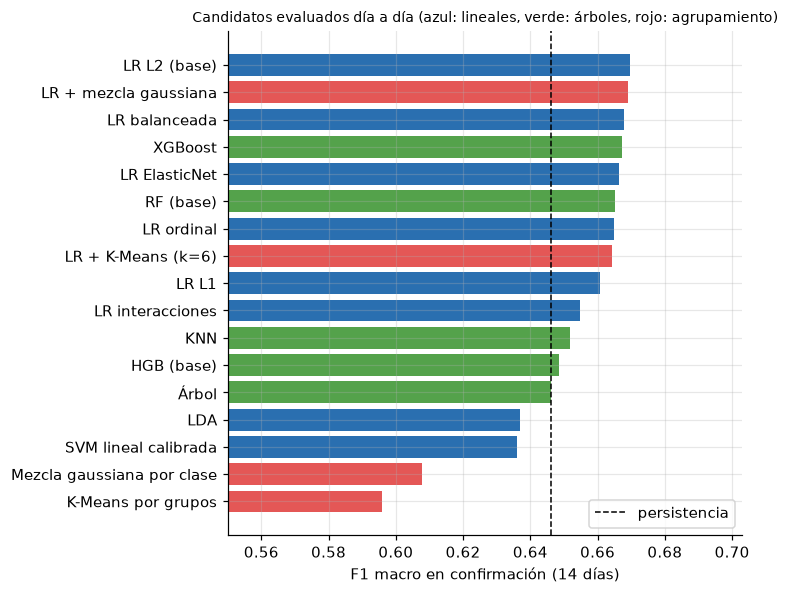

In [14]:
def fila_metricas(cms, idx):
    m = _met_cm(cms[idx].sum(0)); return {k: m[k] for k in ('exactitud', 'F1 macro', 'kappa', 'precisión de bajo', 'recall de bajo', 'falsos bajo')}
PREVIO = ['LR L2 (base)', 'HGB (base)', 'RF (base)']
PRED = {n: PROB[n].argmax(1) for n in PROB}
PRED['Persistencia'] = META['Persistencia'].to_numpy(); PRED['Combinación persistencia-climatología'] = META['Combinación persistencia-climatología'].to_numpy()
PRED['Ensamble previo (LR + HGB + RF)'] = np.mean([PROB[n] for n in PREVIO], axis=0).argmax(1)
CMS = {n: cms_por_dia(p) for n, p in PRED.items()}
t_ind = pd.DataFrame({n: {**{f'{k} (desarrollo)': v for k, v in fila_metricas(c_, DES_I).items() if k in ('F1 macro', 'kappa')},
                          **{f'{k} (confirmación)': v for k, v in fila_metricas(c_, CONF_I).items()}} for n, c_ in CMS.items()}).T.sort_values('F1 macro (confirmación)', ascending=False)
display(t_ind.round(3))
rng_b = np.random.default_rng(SEMILLA); IX_BOOT = rng_b.integers(0, len(CONF_I), (N_BOOT, len(CONF_I)))
def boot_dif(nombre_a, nombre_b, metricas_=('precisión de bajo', 'F1 macro', 'kappa'), idx=None, ix_boot=None):
    idx = CONF_I if idx is None else idx; ix_boot = IX_BOOT if ix_boot is None else ix_boot
    ca, cb = CMS[nombre_a][idx], CMS[nombre_b][idx]; obs_a, obs_b = _met_cm(ca.sum(0)), _met_cm(cb.sum(0)); dif = {k: [] for k in metricas_}
    for ix in ix_boot:
        ma, mb = _met_cm(ca[ix].sum(0)), _met_cm(cb[ix].sum(0))
        for k in metricas_: dif[k].append(ma[k] - mb[k])
    return {k: (obs_a[k] - obs_b[k], np.nanpercentile(dif[k], 2.5), np.nanpercentile(dif[k], 97.5)) for k in metricas_}
fig, ax = plt.subplots(figsize=(7, 5.5))
cand = [n for n in PROB]; vals = [fila_metricas(CMS[n], CONF_I)['F1 macro'] for n in cand]
col_f = {'Lineales': '#2a6fb0', 'Árboles, boosting y vecinos': '#54a24b', 'Con agrupamiento': '#e45756'}
fam_wf = {n: FAMILIA.get(n, FAMILIA.get({'LR L2 (base)': 'Regresión logística', 'HGB (base)': 'HistGradientBoosting', 'RF (base)': 'Random Forest'}.get(n, ''), 'Lineales')) for n in cand}
o_ = np.argsort(vals); ax.barh([cand[i] for i in o_], [vals[i] for i in o_], color=[col_f[fam_wf[cand[i]]] for i in o_])
ax.axvline(fila_metricas(CMS['Persistencia'], CONF_I)['F1 macro'], color='k', ls='--', lw=1, label='persistencia'); ax.set_xlim(.55, None); ax.legend(loc='lower right')
ax.set_xlabel('F1 macro en confirmación (14 días)'); ax.set_title('Candidatos evaluados día a día (azul: lineales, verde: árboles, rojo: agrupamiento)', fontsize=9)
fig.tight_layout(); fig.savefig('figuras/f4_candidatos_dia_a_dia.png', dpi=200, bbox_inches='tight'); plt.show()

El primer vistazo a los 17 candidatos evaluados día a día muestra una banda estrecha: casi todos quedan entre 0,64 y 0,68 de F1 macro en confirmación, y el ensamble previo de tres modelos (logística, boosting y bosque) lidera con 0,678. La persistencia (0,646) queda cerca de la cola de esa banda, lo que significa que la mayoría de los modelos la supera, pero por poco. Los dos modelos que usan los grupos de instantes de forma directa, sin pasar por una logística, están claramente por debajo, algo que se confirma con intervalos en B.3.

In [15]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score

## B.2 Variantes de la regresión logística frente a la logística de referencia
Cada variante se compara con la logística L2 en los días de confirmación, con intervalos de 95 % por bootstrap de días. El azul marca los intervalos que excluyen 0.

,modelo,métrica,diferencia,IC95 inferior,IC95 superior,el IC excluye 0
0,LR L1,precisión de bajo,-0.006,-0.014,0.000,False
1,LR L1,F1 macro,-0.009,-0.022,0.001,False
2,LR L1,kappa,-0.010,-0.023,0.002,False
3,LR ElasticNet,precisión de bajo,0.000,-0.009,0.009,False
4,LR ElasticNet,F1 macro,-0.003,-0.016,0.005,False
5,LR ElasticNet,kappa,-0.001,-0.011,0.009,False
6,LR interacciones,precisión de bajo,0.003,-0.028,0.038,False
7,LR interacciones,F1 macro,-0.015,-0.054,0.022,False
8,LR interacciones,kappa,-0.024,-0.061,0.015,False
9,LR balanceada,precisión de bajo,0.000,-0.009,0.009,False


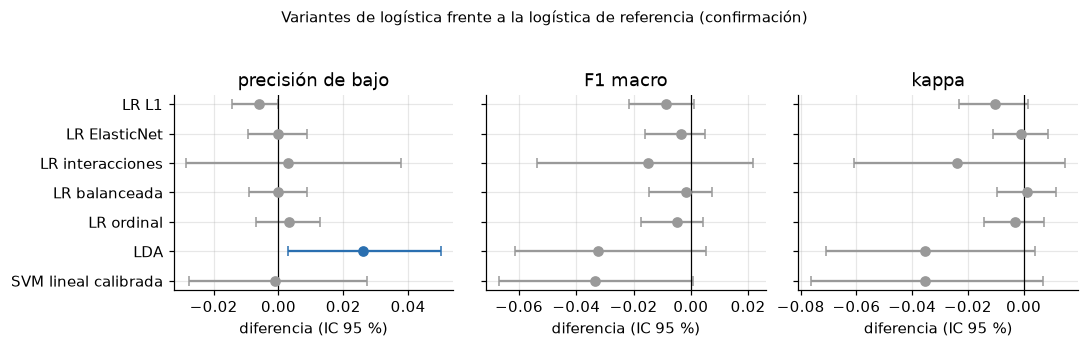

In [16]:
GRUPO_LR = ['LR L2 (base)', 'LR L1', 'LR ElasticNet', 'LR interacciones', 'LR balanceada', 'LR ordinal', 'LDA', 'SVM lineal calibrada']
GRUPO_CLUSTER = ['LR + K-Means (k=6)', 'LR + mezcla gaussiana', 'K-Means por grupos', 'Mezcla gaussiana por clase']
METRICAS_B = ('precisión de bajo', 'F1 macro', 'kappa')
def comparar(modelos, referencia='LR L2 (base)'):
    filas = []
    for n in modelos:
        for k, (d_, lo, hi) in boot_dif(n, referencia, METRICAS_B).items():
            filas.append({'modelo': n, 'métrica': k, 'diferencia': d_, 'IC95 inferior': lo, 'IC95 superior': hi, 'el IC excluye 0': (lo > 0) or (hi < 0)})
    return pd.DataFrame(filas)
def dibujar(t, modelos, titulo, archivo):
    fig, ax = plt.subplots(1, 3, figsize=(10, 3 if len(modelos) > 4 else 2.4), sharey=True)
    for a_, k in zip(ax, METRICAS_B):
        s = t[t['métrica'] == k].reset_index(drop=True)
        for i, r in s.iterrows():
            a_.errorbar(r['diferencia'], i, xerr=[[r['diferencia'] - r['IC95 inferior']], [r['IC95 superior'] - r['diferencia']]], fmt='o', capsize=3,
                        color='#2a6fb0' if r['el IC excluye 0'] else '#999999')
        a_.axvline(0, color='k', lw=.8); a_.set_title(k); a_.set_xlabel('diferencia (IC 95 %)')
    ax[0].set_yticks(range(len(modelos))); ax[0].set_yticklabels(modelos); ax[0].invert_yaxis()
    fig.suptitle(titulo, fontsize=10, y=1.04); fig.tight_layout(); fig.savefig(archivo, dpi=200, bbox_inches='tight'); plt.show()
t_lr = comparar(GRUPO_LR[1:]); display(t_lr.round(3))
dibujar(t_lr, GRUPO_LR[1:], 'Variantes de logística frente a la logística de referencia (confirmación)', 'figuras/fB_variantes_logistica.png')
t_lr.to_csv('figuras/res_variantes_logistica.csv', index=False, encoding='utf-8-sig')

Ninguna variante mejora a la logística L2 en F1 macro ni en kappa: todas las diferencias están dentro de ruido, con intervalos que incluyen 0. Las penalizaciones L1 y ElasticNet, los pesos balanceados y el enfoque ordinal cambian el resultado en menos de una centésima, lo que indica que con tan pocos días la forma de la regularización es casi irrelevante. La única excepción en la dirección contraria es el LDA, que gana 2,6 puntos de precisión de bajo con intervalo que excluye 0, pero pierde unos 3 puntos de F1 macro y de kappa (con intervalos que incluyen 0): es una versión más conservadora, que dice bajo menos veces y por eso acierta más cuando lo dice. Las interacciones y la SVM lineal quedan peor en promedio; las interacciones, con más de 200 columnas para solo 27 días de entrenamiento, sobreajustan.

## B.3 Modelos con agrupamiento de instantes frente a la logística de referencia
Los grupos se calculan solo con las variables de entrada (distancias a los centros de K-Means o probabilidades de una mezcla gaussiana agregadas a la logística, K-Means como clasificador por grupos y una mezcla gaussiana por clase). Ninguno usa información del futuro.

,modelo,métrica,diferencia,IC95 inferior,IC95 superior,el IC excluye 0
0,LR + K-Means (k=6),precisión de bajo,-0.010,-0.030,0.007,False
1,LR + K-Means (k=6),F1 macro,-0.005,-0.023,0.010,False
2,LR + K-Means (k=6),kappa,-0.002,-0.022,0.019,False
3,LR + mezcla gaussiana,precisión de bajo,0.003,-0.019,0.025,False
4,LR + mezcla gaussiana,F1 macro,-0.001,-0.010,0.008,False
5,LR + mezcla gaussiana,kappa,0.000,-0.018,0.021,False
6,K-Means por grupos,precisión de bajo,-0.067,-0.111,-0.030,True
7,K-Means por grupos,F1 macro,-0.074,-0.107,-0.045,True
8,K-Means por grupos,kappa,-0.134,-0.175,-0.098,True
9,Mezcla gaussiana por clase,precisión de bajo,-0.042,-0.082,-0.007,True


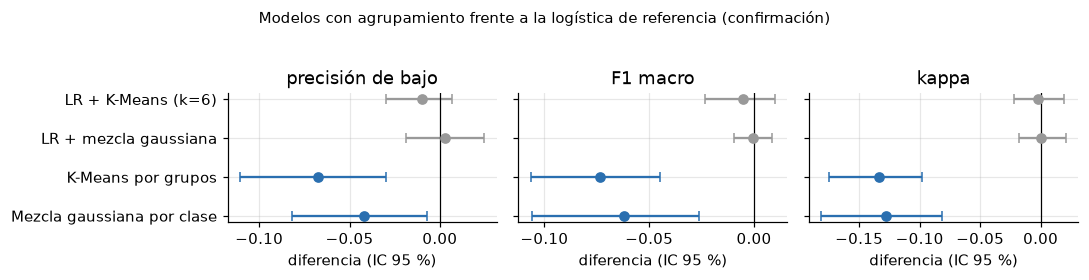

In [17]:
t_cl = comparar(GRUPO_CLUSTER); display(t_cl.round(3))
dibujar(t_cl, GRUPO_CLUSTER, 'Modelos con agrupamiento frente a la logística de referencia (confirmación)', 'figuras/fB_modelos_agrupamiento.png')
t_cl.to_csv('figuras/res_modelos_agrupamiento.csv', index=False, encoding='utf-8-sig')

Agregar a la logística las distancias a los grupos de K-Means o las probabilidades de una mezcla gaussiana no cambia su desempeño como modelo suelto (diferencias de una centésima o menos, con intervalos que incluyen 0). En cambio, usar los grupos como clasificador directo es claramente peor: el kappa baja unos 13 puntos con K-Means por grupos y con la mezcla gaussiana por clase, con intervalos que excluyen 0. La lectura es que los grupos de instantes no tienen estructura suficiente para decidir el nivel por sí solos, pero sí aportan una mirada distinta de los datos; esa diversidad es lo que luego se aprovecha dentro del ensamble, y por eso la logística con distancias a K-Means aparece en la receta final aunque como modelo suelto no gane.

## B.4 Combinatoria de ensambles: efecto del tamaño
Se promedian con pesos iguales todos los subconjuntos de 2 a 5 de los 17 candidatos y se evalúan día a día. Aquí se mira qué pasa con el desempeño según cuántos modelos se combinan, y cuánto se parece el orden en desarrollo al orden en confirmación.

17 candidatos, 9384 combinaciones de 2 a 5 modelos.
Las 10 mejores combinaciones según los días de DESARROLLO (y cómo les fue en confirmación):


,modelos,tamaño,F1 des,F1 conf,kappa conf,prec bajo conf,recall bajo conf,falsos bajo conf
0,RF (base) + LR L1 + LR balanceada + LR + K-Mea...,5,0.774,0.674,0.615,0.870,0.834,36
1,RF (base) + LR ElasticNet + LR balanceada + LR...,5,0.774,0.677,0.620,0.873,0.834,35
2,RF (base) + LR ElasticNet + Árbol,3,0.774,0.659,0.595,0.891,0.792,28
3,LR L2 (base) + LR ElasticNet + LR balanceada +...,5,0.773,0.665,0.598,0.866,0.827,37
4,RF (base) + LR L1 + Árbol,3,0.772,0.665,0.597,0.888,0.792,29
5,HGB (base) + RF (base) + LDA + SVM lineal cali...,5,0.772,0.669,0.608,0.895,0.796,27
6,LR L2 (base) + RF (base) + LR interacciones + ...,5,0.771,0.677,0.608,0.876,0.810,33
7,RF (base) + LR + mezcla gaussiana + XGBoost,3,0.771,0.673,0.606,0.872,0.803,34
8,LR L2 (base) + RF (base) + LR ElasticNet + LR ...,5,0.771,0.674,0.612,0.866,0.830,37
9,RF (base) + LR + mezcla gaussiana + Árbol,3,0.770,0.659,0.595,0.888,0.792,29


Mejor combinación de cada tamaño según DESARROLLO:


,modelos,tamaño,F1 des,F1 conf,kappa conf,prec bajo conf,recall bajo conf,falsos bajo conf
0,RF (base) + LR L1 + LR balanceada + LR + K-Mea...,5,0.774,0.674,0.615,0.870,0.834,36
2,RF (base) + LR ElasticNet + Árbol,3,0.774,0.659,0.595,0.891,0.792,28
11,RF (base) + LR + K-Means (k=6),2,0.770,0.688,0.620,0.864,0.817,37
13,HGB (base) + RF (base) + LR + mezcla gaussiana...,4,0.770,0.667,0.599,0.891,0.789,28


Correlación de Spearman entre desarrollo y confirmación (todas las combinaciones): F1 macro +0.28, kappa +0.27
La mejor en desarrollo queda en el percentil 65 de F1 macro en confirmación.


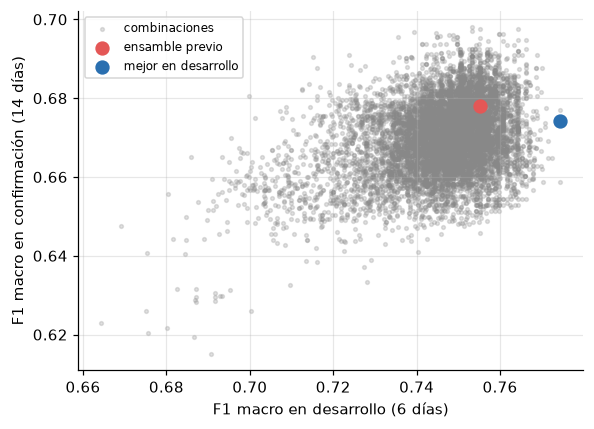

In [18]:
POOL = list(PROB); S = np.stack([PROB[n] for n in POOL])                    # (modelos, instantes, 3)
TAM_MAX = 5
DES2_I = np.array([i for i, d_ in enumerate(DIAS_WF) if d_ < WF_DIA_INICIO + 10]); CONF2_I = np.array([i for i, d_ in enumerate(DIAS_WF) if d_ >= WF_DIA_INICIO + 10])
filas_c = []
for r_ in range(2, TAM_MAX + 1):
    for ix in itertools.combinations(range(len(POOL)), r_):
        cms_ = cms_por_dia(S[list(ix)].mean(0).argmax(1)); md_, mc_, m2d_, m2c_ = (_met_cm(cms_[i].sum(0)) for i in (DES_I, CONF_I, DES2_I, CONF2_I))
        filas_c.append({'comb': ix, 'tamaño': r_, 'F1 des': md_['F1 macro'], 'kappa des': md_['kappa'], 'F1 conf': mc_['F1 macro'], 'kappa conf': mc_['kappa'],
                        'prec bajo conf': mc_['precisión de bajo'], 'recall bajo conf': mc_['recall de bajo'], 'falsos bajo conf': mc_['falsos bajo'],
                        'F1 des2': m2d_['F1 macro'], 'kappa des2': m2d_['kappa'], 'F1 conf2': m2c_['F1 macro'], 'kappa conf2': m2c_['kappa']})
COMB = pd.DataFrame(filas_c); COMB['modelos'] = COMB.comb.map(lambda ix: ' + '.join(POOL[i] for i in ix))
ix_previo = tuple(sorted(POOL.index(n) for n in PREVIO)); fila_previo = COMB[COMB.comb.map(lambda t: t == ix_previo)].iloc[0]
print(f'{len(POOL)} candidatos, {len(COMB)} combinaciones de 2 a {TAM_MAX} modelos.')
orden_des = COMB.sort_values(['F1 des', 'kappa des'], ascending=False).reset_index(drop=True)
cols_t = ['modelos', 'tamaño', 'F1 des', 'F1 conf', 'kappa conf', 'prec bajo conf', 'recall bajo conf', 'falsos bajo conf']
print('Las 10 mejores combinaciones según los días de DESARROLLO (y cómo les fue en confirmación):'); display(orden_des[cols_t].head(10).round(3))
print('Mejor combinación de cada tamaño según DESARROLLO:'); display(orden_des.groupby('tamaño').head(1)[cols_t].round(3))
rho = COMB[['F1 des', 'F1 conf']].corr(method='spearman').iloc[0, 1]; rho_k = COMB[['kappa des', 'kappa conf']].corr(method='spearman').iloc[0, 1]
print(f'Correlación de Spearman entre desarrollo y confirmación (todas las combinaciones): F1 macro {rho:+.2f}, kappa {rho_k:+.2f}')
print(f'La mejor en desarrollo queda en el percentil {100 * (COMB["F1 conf"] <= orden_des.loc[0, "F1 conf"]).mean():.0f} de F1 macro en confirmación.')
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(COMB['F1 des'], COMB['F1 conf'], s=6, alpha=.25, color='#888888', label='combinaciones')
ax.scatter(fila_previo['F1 des'], fila_previo['F1 conf'], s=70, color='#e45756', zorder=3, label='ensamble previo')
ax.scatter(orden_des.loc[0, 'F1 des'], orden_des.loc[0, 'F1 conf'], s=70, color='#2a6fb0', zorder=3, label='mejor en desarrollo')
ax.set_xlabel('F1 macro en desarrollo (6 días)'); ax.set_ylabel('F1 macro en confirmación (14 días)'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig('figuras/f4_combinatoria_dev_conf.png', dpi=200, bbox_inches='tight'); plt.show()
COMB.drop(columns=['comb']).to_csv('figuras/res_combinatoria.csv', index=False, encoding='utf-8-sig')

,combinaciones,F1_conf_media,F1_conf_mejor,F1_conf_peor,prec_bajo_media,recall_bajo_media
tamaño,,,,,,
2,136,0.657,0.688,0.615,0.866,0.805
3,680,0.665,0.693,0.630,0.870,0.811
4,2380,0.669,0.698,0.642,0.872,0.815
5,6188,0.671,0.698,0.643,0.874,0.816


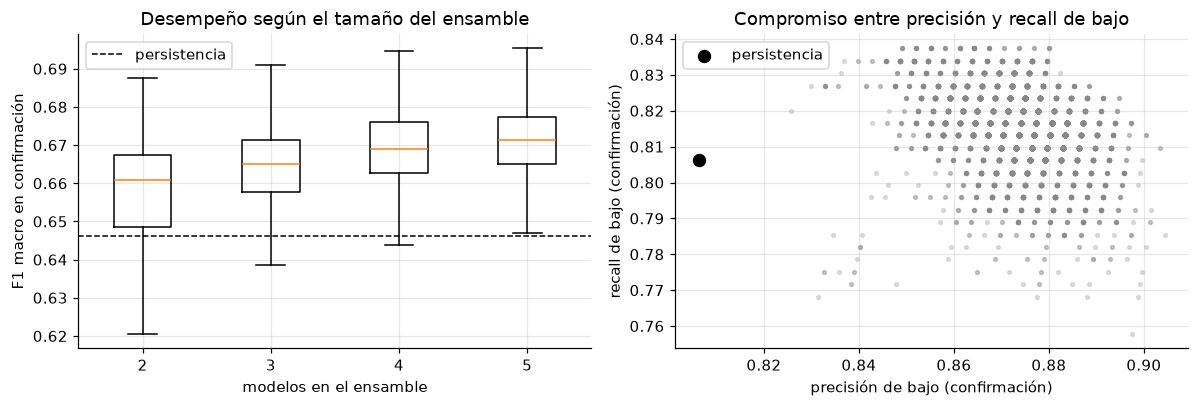

,modelos,tamaño,F1 primeros 10 días,F1 últimos 10 días,kappa últimos 10 días
3284,LR L2 (base) + HGB (base) + RF (base) + XGBoos...,5,0.762,0.672,0.604
5257,HGB (base) + RF (base) + LR balanceada + XGBoo...,5,0.762,0.672,0.604
5367,HGB (base) + RF (base) + LR + mezcla gaussiana...,5,0.761,0.676,0.611
2147,RF (base) + SVM lineal calibrada + LR + mezcla...,4,0.761,0.685,0.614
439,RF (base) + LR + mezcla gaussiana + XGBoost,3,0.761,0.676,0.606


In [19]:
por_tam = COMB.groupby('tamaño').agg(combinaciones=('F1 conf', 'size'), F1_conf_media=('F1 conf', 'mean'), F1_conf_mejor=('F1 conf', 'max'), F1_conf_peor=('F1 conf', 'min'),
                                     prec_bajo_media=('prec bajo conf', 'mean'), recall_bajo_media=('recall bajo conf', 'mean')).round(3)
display(por_tam)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].boxplot([COMB.loc[COMB['tamaño'] == t, 'F1 conf'] for t in range(2, TAM_MAX + 1)], tick_labels=list(range(2, TAM_MAX + 1)), showfliers=False)
ax[0].axhline(fila_metricas(CMS['Persistencia'], CONF_I)['F1 macro'], color='k', ls='--', lw=1, label='persistencia'); ax[0].legend()
ax[0].set_xlabel('modelos en el ensamble'); ax[0].set_ylabel('F1 macro en confirmación'); ax[0].set_title('Desempeño según el tamaño del ensamble')
ax[1].scatter(COMB['prec bajo conf'], COMB['recall bajo conf'], s=6, alpha=.25, color='#888888')
ax[1].scatter(fila_metricas(CMS['Persistencia'], CONF_I)['precisión de bajo'], fila_metricas(CMS['Persistencia'], CONF_I)['recall de bajo'], color='k', s=60, label='persistencia', zorder=3)
ax[1].set_xlabel('precisión de bajo (confirmación)'); ax[1].set_ylabel('recall de bajo (confirmación)'); ax[1].set_title('Compromiso entre precisión y recall de bajo'); ax[1].legend()
fig.tight_layout(); fig.savefig('figuras/fB_combinatoria_tamano.png', dpi=200, bbox_inches='tight'); plt.show()
display(COMB.sort_values('F1 des2', ascending=False)[['modelos', 'tamaño', 'F1 des2', 'F1 conf2', 'kappa conf2']].head(5).round(3).rename(columns={'F1 des2': 'F1 primeros 10 días', 'F1 conf2': 'F1 últimos 10 días', 'kappa conf2': 'kappa últimos 10 días'}))

Al aumentar el tamaño del ensamble, el desempeño medio sube (de 0,657 con dos modelos a 0,671 con cinco) y también el mejor caso (de 0,688 a 0,698), pero con rendimientos decrecientes: pasar de cuatro a cinco modelos aporta apenas dos milésimas. La precisión de bajo prácticamente no depende del tamaño (0,87 en todos) y el recall sube solo de 0,805 a 0,816, de modo que combinar ayuda sobre todo a que los errores se compensen, no a cambiar el tipo de errores. A la derecha se ve el compromiso entre precisión y recall: la persistencia queda a la izquierda de casi toda la nube, es decir, casi cualquier ensamble le gana en precisión a igual recall. La tabla final es una advertencia: con los primeros diez días como desarrollo, el primer puesto lo ocupa una receta distinta a la elegida (con boosting, XGBoost y vecinos), lo que muestra otra vez qué tanto depende el ranking del tramo de días con que se mire.

## B.5 Agrupamiento de días: alternativas a K-Means
El cuaderno principal agrupa los días con K-Means. Aquí se comparan otros métodos con el mismo número de grupos. Es una comparación descriptiva: el tipo de día no entra al modelo. El error del ensamble por grupo se calcula con las predicciones día a día de los siete días de prueba.

,energia_MWh,irr_kWh_m2,rendimiento_MWh_por_kWhm2,hora_pico,variabilidad_irr,inv_cero_prom
fecha,,,,,,
2020-05-15,162.86,7.14,22.81,9.25,0.05,2.83
2020-05-16,138.56,5.92,23.41,9.50,0.09,2.20
2020-05-17,136.10,5.31,25.64,9.25,0.07,1.19
2020-05-18,129.75,5.37,24.14,12.50,0.07,2.83
2020-05-19,108.39,5.09,21.31,14.25,0.08,2.90
2020-05-20,149.87,6.70,22.38,15.00,0.04,3.18
2020-05-21,156.23,6.80,22.98,13.75,0.05,2.67
2020-05-22,160.49,7.13,22.50,15.00,0.04,3.52


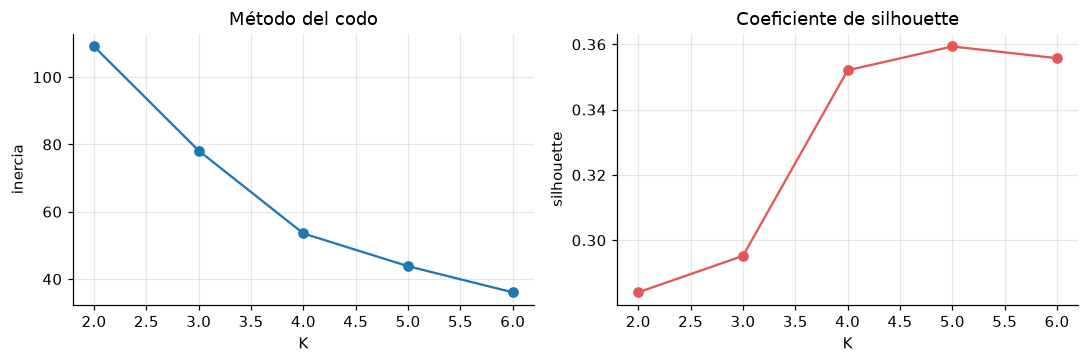

Silhouette por K: {2: np.float64(0.284), 3: np.float64(0.295), 4: np.float64(0.352), 5: np.float64(0.359), 6: np.float64(0.356)}


In [20]:
K_MAX = 6                            # con ~27 días de entrenamiento, más de 6 grupos deja grupos de 2 o 3 días (supuesto del equipo, 4.5)
def tabla_dias(D):
    x = D[~D.imputado]
    g = x.groupby('fecha')
    out = pd.DataFrame({'energia_MWh': g.AC_PLANTA_KW.sum() * 0.25 / 1000, 'irr_kWh_m2': g.IRRADIATION.sum() * 0.25})
    out['rendimiento_MWh_por_kWhm2'] = out.energia_MWh / out.irr_kWh_m2
    s = x[x.IRRADIATION > UMBRAL_IRR]; gs = s.groupby('fecha')
    out['hora_pico'] = gs.apply(lambda q: q.loc[q.AC_PLANTA_KW.idxmax(), 'hora'], include_groups=False)
    out['variabilidad_irr'] = gs.IRRADIATION.apply(lambda q: q.diff().abs().mean())
    out['inv_cero_prom'] = gs.n_inv_cero.mean()
    return out
dias_df = tabla_dias(D)
VARS_K = list(dias_df.columns)
dtr, dte = dias_df.loc[dias_train], dias_df.loc[dias_test]
esc_k = StandardScaler().fit(dtr[VARS_K]); Xk_tr, Xk_te = esc_k.transform(dtr[VARS_K]), esc_k.transform(dte[VARS_K])
display(dias_df.round(2).head(8))

ks = range(2, K_MAX + 1); inercia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Xk_tr)
    inercia.append(km.inertia_); sil.append(silhouette_score(Xk_tr, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(list(ks), inercia, 'o-'); ax[0].set_xlabel('K'); ax[0].set_ylabel('inercia'); ax[0].set_title('Método del codo')
ax[1].plot(list(ks), sil, 'o-', color='#e45756'); ax[1].set_xlabel('K'); ax[1].set_ylabel('silhouette'); ax[1].set_title('Coeficiente de silhouette')
fig.tight_layout(); fig.savefig('figuras/f4_codo_silhouette.png', dpi=200, bbox_inches='tight'); plt.show()
print('Silhouette por K:', dict(zip(ks, np.round(sil, 3))))

In [21]:
K_ELEGIDO = 4                        # decisión del equipo: K = 4; None = el de mayor silhouette entre 2 y K_MAX (decisión 4.5.1)
K = K_ELEGIDO or list(ks)[int(np.argmax(sil))]
print('K usado:', K)

K usado: 4


In [22]:
ENS_MODELOS = ['Random Forest', 'Regresión logística (ElasticNet)', 'SVM lineal calibrada', 'Regresión logística + K-Means']   # cuatro modelos, pesos iguales (decisión 4.4.3)
ENS_WF = {'Random Forest': 'RF (base)', 'Regresión logística (ElasticNet)': 'LR ElasticNet', 'SVM lineal calibrada': 'SVM lineal calibrada', 'Regresión logística + K-Means': 'LR + K-Means (k=6)'}
ix_ens = tuple(sorted(POOL.index(ENS_WF[n]) for n in ENS_MODELOS)); fila_ens = COMB[COMB.comb.map(lambda t: t == ix_ens)].iloc[0]
print('Percentil de F1 macro del ensamble en cada evaluación (1 = la mejor de las 9 384):',
      {k: round(float((COMB[k] <= fila_ens[k]).mean()), 3) for k in ['F1 des', 'F1 conf', 'F1 des2', 'F1 conf2']})
print(f'Ensamble: F1 des {fila_ens["F1 des"]:.3f}, F1 conf {fila_ens["F1 conf"]:.3f}, kappa conf {fila_ens["kappa conf"]:.3f}, precisión de bajo {fila_ens["prec bajo conf"]:.3f}, recall de bajo {fila_ens["recall bajo conf"]:.3f}')
print(f'Ensamble previo: F1 des {fila_previo["F1 des"]:.3f}, F1 conf {fila_previo["F1 conf"]:.3f}, kappa conf {fila_previo["kappa conf"]:.3f}, precisión de bajo {fila_previo["prec bajo conf"]:.3f}, recall de bajo {fila_previo["recall bajo conf"]:.3f}')

Percentil de F1 macro del ensamble en cada evaluación (1 = la mejor de las 9 384): {'F1 des': 0.992, 'F1 conf': 0.998, 'F1 des2': 0.985, 'F1 conf2': 0.998}
Ensamble: F1 des 0.766, F1 conf 0.695, kappa conf 0.635, precisión de bajo 0.875, recall de bajo 0.827
Ensamble previo: F1 des 0.755, F1 conf 0.678, kappa conf 0.609, precisión de bajo 0.875, recall de bajo 0.799


In [23]:
mask_te = META.dia_idx.isin(range(len(dias_train), len(ctx['dias']))).to_numpy()
pred_final_te = np.mean([PROB[ENS_WF[n]] for n in ENS_MODELOS], axis=0).argmax(1)[mask_te]
y_te_ = META.real.to_numpy()[mask_te]
fecha_te = ctx['dias'][META.dia_idx[mask_te].to_numpy()]
# ---- Clustering de días: alternativas a K-Means (descriptivo; no entra al modelo) ----
KG = K
def asignar_centroide(Xtr_, lab_, Xnew_):
    gs_ = np.unique(lab_); cents = np.array([Xtr_[lab_ == g].mean(0) for g in gs_])
    return gs_[np.argmin(((Xnew_[:, None, :] - cents[None]) ** 2).sum(2), 1)]

def metodo(nombre, X):
    """Ajusta el método con X y devuelve (etiquetas de X, función que asigna días nuevos)."""
    if nombre == 'K-Means':
        m = KMeans(KG, n_init=10, random_state=SEMILLA).fit(X); return m.labels_, m.predict
    if nombre == 'Jerárquico (Ward)':
        m = AgglomerativeClustering(KG, linkage='ward').fit(X); return m.labels_, lambda Z: asignar_centroide(X, m.labels_, Z)
    if nombre == 'Jerárquico (enlace promedio)':
        m = AgglomerativeClustering(KG, linkage='average').fit(X); return m.labels_, lambda Z: asignar_centroide(X, m.labels_, Z)
    if nombre == 'Mezcla gaussiana (diagonal)':
        m = GaussianMixture(KG, covariance_type='diag', reg_covar=1e-2, n_init=10, random_state=SEMILLA).fit(X); return m.predict(X), m.predict
    if nombre == 'Mezcla gaussiana (esférica)':
        m = GaussianMixture(KG, covariance_type='spherical', reg_covar=1e-2, n_init=10, random_state=SEMILLA).fit(X); return m.predict(X), m.predict
METODOS_DIAS = ['K-Means', 'Jerárquico (Ward)', 'Jerárquico (enlace promedio)', 'Mezcla gaussiana (diagonal)', 'Mezcla gaussiana (esférica)']
lab_km, _ = metodo('K-Means', Xk_tr)
rng_s = np.random.default_rng(SEMILLA); filas_d, ETIQ_DIAS = [], {}
for nom in METODOS_DIAS:
    lab, asignar = metodo(nom, Xk_tr); lab_te = asignar(Xk_te); ETIQ_DIAS[nom] = (lab, lab_te)
    tam = np.bincount(lab, minlength=KG)
    # estabilidad: se vuelven a ajustar con días de entrenamiento remuestreados y se compara con el ajuste completo
    aris = []
    for _ in range(100):
        ix = np.unique(rng_s.integers(0, len(Xk_tr), len(Xk_tr)))
        if len(ix) <= KG: continue
        try:
            _, asg = metodo(nom, Xk_tr[ix]); aris.append(adjusted_rand_score(lab, asg(Xk_tr)))
        except Exception:
            pass
    dia_grp_te = pd.Series(lab_te, index=dte.index)
    err_g = {g: 100 * (y_te_[pd.Series(fecha_te).map(dia_grp_te).to_numpy() == g] != pred_final_te[pd.Series(fecha_te).map(dia_grp_te).to_numpy() == g]).mean()
             for g in np.unique(lab_te)}
    filas_d.append({'método': nom, 'silhouette': silhouette_score(Xk_tr, lab) if len(np.unique(lab)) > 1 else np.nan,
                    'tamaños de los grupos (entrenamiento)': ' / '.join(map(str, sorted(tam, reverse=True))),
                    'grupos con 2 días o menos': int((tam <= 2).sum()), 'ARI frente a K-Means': adjusted_rand_score(lab_km, lab),
                    'estabilidad (ARI medio con remuestreo)': float(np.mean(aris)) if aris else np.nan,
                    'grupos presentes en prueba': len(err_g), 'error del ensamble por grupo en prueba (%)': ', '.join(f'{v:.0f}' for v in err_g.values())})
t_dias = pd.DataFrame(filas_d).set_index('método'); print(f'Agrupación de {len(Xk_tr)} días de entrenamiento con K = {KG}:'); display(t_dias.round(3))
t_dias.to_csv('figuras/res_clustering_dias.csv', encoding='utf-8-sig')

# Elección del número de grupos con otros criterios (BIC de la mezcla gaussiana) y DBSCAN
filas_k = []
for k_ in range(2, K_MAX + 1):
    gm_ = GaussianMixture(k_, covariance_type='diag', reg_covar=1e-2, n_init=10, random_state=SEMILLA).fit(Xk_tr)
    km_ = KMeans(k_, n_init=10, random_state=SEMILLA).fit(Xk_tr); ag_ = AgglomerativeClustering(k_, linkage='ward').fit(Xk_tr)
    filas_k.append({'K': k_, 'silhouette K-Means': silhouette_score(Xk_tr, km_.labels_), 'silhouette Ward': silhouette_score(Xk_tr, ag_.labels_),
                    'BIC mezcla gaussiana': gm_.bic(Xk_tr)})
print('Número de grupos según cada criterio:'); display(pd.DataFrame(filas_k).set_index('K').round(3))
filas_db = []
for eps_ in (0.8, 1.0, 1.3, 1.6, 2.0, 2.5):
    lab_db = DBSCAN(eps=eps_, min_samples=2).fit_predict(Xk_tr)
    filas_db.append({'eps': eps_, 'grupos': len(set(lab_db) - {-1}), 'días sin grupo (ruido)': int((lab_db == -1).sum())})
print('DBSCAN (min_samples = 2):'); display(pd.DataFrame(filas_db).set_index('eps'))

Agrupación de 27 días de entrenamiento con K = 4:


,silhouette,tamaños de los grupos (entrenamiento),grupos con 2 días o menos,ARI frente a K-Means,estabilidad (ARI medio con remuestreo),grupos presentes en prueba,error del ensamble por grupo en prueba (%)
método,,,,,,,
K-Means,0.352,10 / 7 / 7 / 3,0,1.000,0.761,2,"18, 24"
Jerárquico (Ward),0.352,11 / 7 / 6 / 3,0,0.882,0.746,2,"24, 18"
Jerárquico (enlace promedio),0.344,11 / 8 / 5 / 3,0,0.722,0.614,2,"24, 18"
Mezcla gaussiana (diagonal),0.341,10 / 9 / 5 / 3,0,0.823,0.572,2,"18, 24"
Mezcla gaussiana (esférica),0.352,11 / 7 / 6 / 3,0,0.882,0.600,2,"24, 18"


Número de grupos según cada criterio:


,silhouette K-Means,silhouette Ward,BIC mezcla gaussiana
K,,,
2,0.284,0.260,454.229
3,0.295,0.300,443.075
4,0.352,0.352,454.362
5,0.359,0.358,455.074
6,0.356,0.352,462.339


DBSCAN (min_samples = 2):


,grupos,días sin grupo (ruido)
eps,,
0.8,2,20
1.0,5,13
1.3,6,9
1.6,5,4
2.0,2,3
2.5,1,1


Cinco métodos distintos dan prácticamente la misma agrupación de los días con K = 4: silhouette entre 0,34 y 0,35, grupos de tamaños parecidos (10, 7, 7 y 3 días con K-Means) y ningún grupo con dos días o menos. Ward y la mezcla gaussiana esférica coinciden con K-Means en un índice de Rand ajustado de 0,88, y K-Means es el más estable al remuestrear los días (0,76 frente a entre 0,57 y 0,75). En los siete días de prueba solo aparecen dos grupos con cualquiera de los métodos y el error del ensamble es el mismo par de valores (18 % y 24 %), de manera que la conclusión sobre el error por tipo de día no depende de qué método de agrupamiento se use. Sobre el número de grupos, el silhouette casi no distingue entre 4, 5 y 6, y el BIC de la mezcla gaussiana prefiere 3; DBSCAN, por su parte, deja entre 1 y 20 días sin grupo según el parámetro eps, señal de que no hay separaciones naturales muy claras. Elegir K = 4 es entonces una decisión práctica, razonable pero no la única posible.

## Referencias

Este anexo no cita fuentes adicionales a las del cuaderno principal.